# Audio Classification with CNN, STT and TTS


## 1. Install and import libraries

Run this cell first. If you install packages in a notebook, restart the kernel only if it asks you to, then continue from the next cell.

In [ ]:
%pip -q install librosa scikit-learn SpeechRecognition pyttsx3 soundfile

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 32.9/32.9 MB 53.9 MB/s eta 0:00:00


In [ ]:
import os
import pathlib
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 2. Automatically download the small dataset

The dataset is downloaded by TensorFlow from its official storage. It contains eight command folders and does not require a manual dataset download.

In [ ]:

import tensorflow as tf
import zipfile
import urllib.request
from pathlib import Path

# Dataset URL
DATA_URL = (
    "http://storage.googleapis.com/download.tensorflow.org/"
    "data/mini_speech_commands.zip"
)

# Check common dataset locations
possible_paths = [
    Path("data/mini_speech_commands"),
    Path("mini_speech_commands"),
    Path("/content/data/mini_speech_commands"),
    Path("/content/mini_speech_commands"),
]

DATA_DIR = next(
    (p for p in possible_paths if p.exists() and any(p.iterdir())),
    None
)

# Download and extract only if the dataset was not found
if DATA_DIR is None:
    data_root = Path("data")
    data_root.mkdir(parents=True, exist_ok=True)

    zip_path = data_root / "mini_speech_commands.zip"

    if not zip_path.exists():
        print("Downloading dataset...")
        urllib.request.urlretrieve(DATA_URL, zip_path)

    print("Extracting dataset...")
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(data_root)

    DATA_DIR = data_root / "mini_speech_commands"

# Verify dataset
print("Dataset folder:", DATA_DIR.resolve())
print("Dataset folder exists:", DATA_DIR.exists())

command_folders = sorted(
    p.name for p in DATA_DIR.iterdir() if p.is_dir()
)

print("Number of command classes:", len(command_folders))
print("Command folders:", command_folders)

assert len(command_folders) > 0, (
    "No command folders found. Check the dataset extraction path."
)


Extracting dataset...
Dataset folder: /content/data/mini_speech_commands
Dataset folder exists: True
Number of command classes: 8
Command folders: ['down', 'go', 'left', 'no', 'right', 'stop', 'up', 'yes']


## 3. Load and prepare audio

Audio is standardized to 16 kHz and one second (16,000 samples). We use an 80/20 training/validation split. The validation set is used for evaluation; for a formal report, describe it as validation performance rather than a completely independent test result.

In [ ]:

import tensorflow as tf

BATCH_SIZE = 32
AUDIO_LENGTH = 16000
SEED = 42

# Load audio without the sampling_rate argument
train_ds = tf.keras.utils.audio_dataset_from_directory(
    DATA_DIR,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    output_sequence_length=AUDIO_LENGTH
)

val_ds = tf.keras.utils.audio_dataset_from_directory(
    DATA_DIR,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    output_sequence_length=AUDIO_LENGTH
)

# Save class names before processing
class_names = train_ds.class_names

print("Classes:", class_names)
print("Number of classes:", len(class_names))

# Convert audio from (batch, samples, 1) to (batch, samples)
def prepare_audio(audio, labels):
    audio = tf.squeeze(audio, axis=-1)
    audio = tf.cast(audio, tf.float32)
    return audio, labels

train_ds = train_ds.map(prepare_audio)
val_ds = val_ds.map(prepare_audio)

# Improve performance
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

# Check one batch
for audio_batch, label_batch in train_ds.take(1):
    print("Audio batch shape:", audio_batch.shape)
    print("Label batch shape:", label_batch.shape)


Found 8000 files belonging to 8 classes.
Using 6400 files for training.
Found 8000 files belonging to 8 classes.
Using 1600 files for validation.
Classes: ['down', 'go', 'left', 'no', 'right', 'stop', 'up', 'yes']
Number of classes: 8
Audio batch shape: (32, 16000)
Label batch shape: (32,)


## 4. Build and train the CNN

The 1D CNN learns local patterns directly from the audio waveform. Early stopping helps reduce overfitting.

In [ ]:
NUM_CLASSES = len(class_names)

print("Number of classes:", NUM_CLASSES)

tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(AUDIO_LENGTH, 1)),
    tf.keras.layers.Conv1D(16, kernel_size=9, strides=2, activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling1D(pool_size=4),

    tf.keras.layers.Conv1D(32, kernel_size=7, activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling1D(pool_size=4),

    tf.keras.layers.Conv1D(64, kernel_size=5, activation="relu"),
    tf.keras.layers.GlobalAveragePooling1D(),

    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=12,
    callbacks=callbacks
)

Number of classes: 8


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_3 (Conv1D)               │ (None, 7996, 16)       │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 7996, 16)       │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 1999, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 1993, 32)       │         3,616 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 1993, 32)       │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 498, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_5 (Conv1D)               │ (None, 494, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_1      │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,952 (74.03 KB)

 Trainable params: 18,856 (73.66 KB)

 Non-trainable params: 96 (384.00 B)

Epoch 1/12
200/200 ━━━━━━━━━━━━━━━━━━━━ 89s 426ms/step - accuracy: 0.3377 - loss: 1.7651 - val_accuracy: 0.1363 - val_loss: 2.4408
Epoch 2/12
200/200 ━━━━━━━━━━━━━━━━━━━━ 62s 310ms/step - accuracy: 0.4923 - loss: 1.4188 - val_accuracy: 0.1675 - val_loss: 3.2798
Epoch 3/12
200/200 ━━━━━━━━━━━━━━━━━━━━ 81s 304ms/step - accuracy: 0.5484 - loss: 1.2940 - val_accuracy: 0.1575 - val_loss: 3.1845
Epoch 4/12
200/200 ━━━━━━━━━━━━━━━━━━━━ 64s 320ms/step - accuracy: 0.5847 - loss: 1.2236 - val_accuracy: 0.2037 - val_loss: 2.3797
Epoch 5/12
200/200 ━━━━━━━━━━━━━━━━━━━━ 63s 315ms/step - accuracy: 0.6028 - loss: 1.1564 - val_accuracy: 0.1881 - val_loss: 7.8142
Epoch 6/12
200/200 ━━━━━━━━━━━━━━━━━━━━ 64s 319ms/step - accuracy: 0.6144 - loss: 1.1186 - val_accuracy: 0.2338 - val_loss: 5.9047
Epoch 7/12
200/200 ━━━━━━━━━━━━━━━━━━━━ 65s 324ms/step - accuracy: 0.6250 - loss: 1.0787 - val_accuracy: 0.2000 - val_loss: 5.2038


## 5. Evaluate the model

We calculate accuracy, per-class precision/recall/F1, macro and weighted averages, and a confusion matrix. Use the actual output values in your assignment report.

Validation Accuracy: 0.2037

Classification Report:
              precision    recall  f1-score   support

        down       0.57      0.07      0.12       185
          go       0.48      0.07      0.12       188
        left       0.15      0.92      0.25       207
          no       0.00      0.00      0.00       207
       right       0.67      0.01      0.02       204
        stop       0.82      0.06      0.12       218
          up       0.19      0.17      0.18       183
         yes       0.95      0.30      0.45       208

    accuracy                           0.20      1600
   macro avg       0.48      0.20      0.16      1600
weighted avg       0.48      0.20      0.16      1600



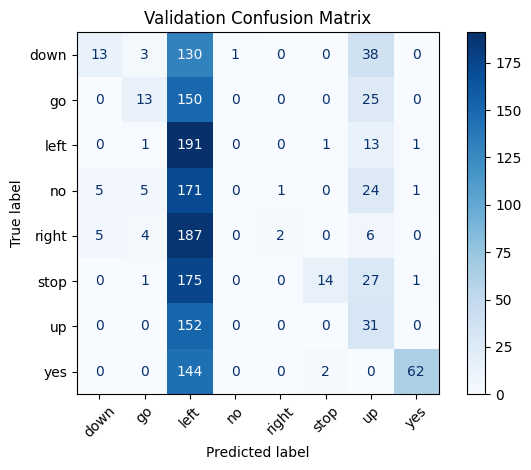

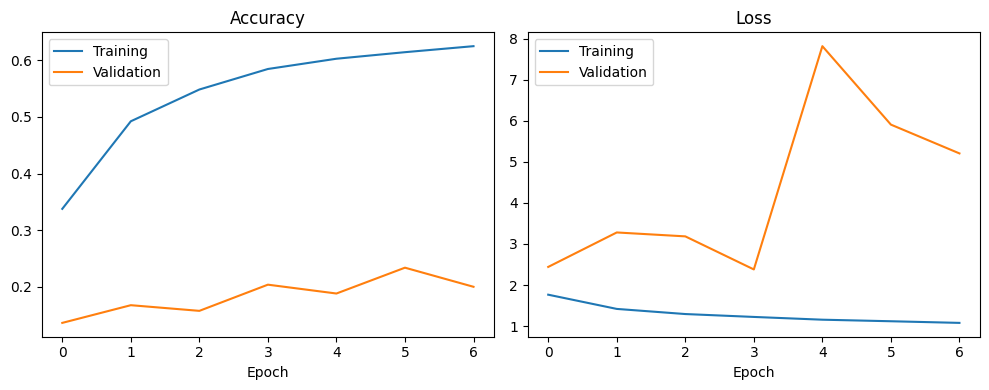

In [ ]:
y_true, y_pred = [], []

for audio_batch, label_batch in val_ds:
    probs = model.predict(audio_batch, verbose=0)
    y_true.extend(label_batch.numpy().tolist())
    y_pred.extend(np.argmax(probs, axis=1).tolist())

print(f"Validation Accuracy: {accuracy_score(y_true, y_pred):.4f}")
print("\nClassification Report:")
print(classification_report(
    y_true, y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(xticks_rotation=45, cmap="Blues")
plt.title("Validation Confusion Matrix")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()
plt.tight_layout()
plt.show()

## 6. Predict a sample from the validation dataset

This demonstrates the classifier output and confidence score.

Actual command: left
Predicted command: left
Confidence: 42.06%


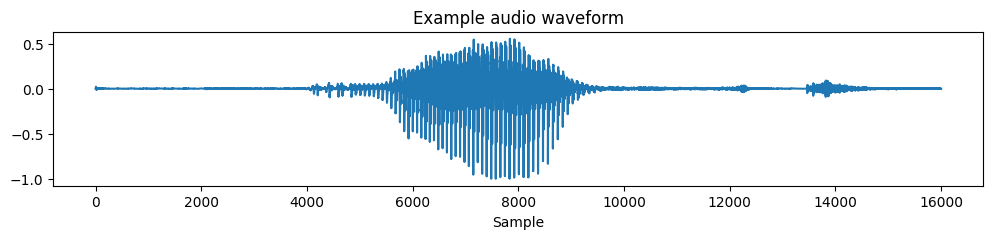

In [ ]:
for audio_batch, label_batch in val_ds.take(1):
    sample = audio_batch[0:1]
    actual_id = int(label_batch[0].numpy())
    probs = model.predict(sample, verbose=0)[0]
    pred_id = int(np.argmax(probs))
    print("Actual command:", class_names[actual_id])
    print("Predicted command:", class_names[pred_id])
    print(f"Confidence: {probs[pred_id] * 100:.2f}%")
    plt.figure(figsize=(12, 2))
    plt.plot(sample.numpy().squeeze())
    plt.title("Example audio waveform")
    plt.xlabel("Sample")
    plt.show()

## 7. Speech-to-Text (STT)

Enter the path to a **WAV** recording containing speech. This example uses Google's online speech-recognition service, so it requires internet access. If STT fails, the audio may be unclear, the service may be unavailable, or the file may not be supported.

In [ ]:
import speech_recognition as sr

audio_path = input("Enter path to a speech WAV file (or press Enter to skip STT): ").strip()

if audio_path and os.path.isfile(audio_path):
    recognizer = sr.Recognizer()
    try:
        with sr.AudioFile(audio_path) as source:
            recorded_audio = recognizer.record(source)
        transcript = recognizer.recognize_google(recorded_audio, language="en-US")
        print("STT transcript:", transcript)
    except sr.UnknownValueError:
        print("Speech could not be understood.")
    except sr.RequestError as exc:
        print("STT service error:", exc)
else:
    print("STT skipped. To try it, provide the path to a WAV speech recording.")

Enter path to a speech WAV file (or press Enter to skip STT): 
STT skipped. To try it, provide the path to a WAV speech recording.


## 8. Text-to-Speech (TTS)

This speaks a text message and also saves it as a WAV file. `pyttsx3` depends on the computer's installed speech engine; some hosted notebook environments may not support audio playback.

In [ ]:
import pyttsx3
from IPython.display import Audio, display

text_to_speak = input("Enter text for TTS (e.g., 'The predicted command is stop'): ").strip()

if text_to_speak:
    try:
        engine = pyttsx3.init()
        output_path = "tts_output.wav"
        engine.save_to_file(text_to_speak, output_path)
        engine.runAndWait()
        engine.stop()

        if os.path.exists(output_path) and os.path.getsize(output_path) > 0:
            print("TTS audio saved to:", output_path)
            display(Audio(filename=output_path))
        else:
            print("TTS engine did not create an audio file in this environment.")
    except Exception as exc:
        print("TTS is not available in this environment:", exc)
else:
    print("TTS skipped.")

Enter text for TTS (e.g., 'The predicted command is stop'): The predicated command is up.
TTS is not available in this environment: This means you probably do not have eSpeak or eSpeak-ng installed!
